# Smart Plant Growth Monitoring and Prediction System
## Machine Learning (ML)

This notebook builds a **baseline regression model** to estimate `New_Growth_Count` from available plant attributes in `cleaned_plant_growth.csv`.

**Important:** This dataset contains recorded growth counts, not clearly time-stamped future measurements. This model estimates the recorded `New_Growth_Count`; it does not directly predict future plant height after a number of days.

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("cleaned_plant_growth.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Target column available:", "New_Growth_Count" in df.columns)
df.head()

Dataset loaded successfully!
Dataset shape: (1000, 29)
Target column available: True


,Plant_ID,Height_cm,Leaf_Count,New_Growth_Count,Health_Notes,Watering_Amount_ml,Watering_Frequency_days,Sunlight_Exposure,Room_Temperature_C,Humidity_%,...,Soil_Type_Silty,Fertilizer_Type_Chemical,Fertilizer_Type_Compost,Fertilizer_Type_Liquid feed,Fertilizer_Type_No fertilizer,Fertilizer_Type_Organic,Pest_Severity_High,Pest_Severity_Low,Pest_Severity_Moderate,Pest_Severity_None
0,Sansevieria cylindrica,17.39,17,8,Yellowing leaves,205,3,3h direct morning sun,21.7,77.5,...,False,False,False,False,False,True,False,False,True,False
1,Aloe vera,9.84,31,9,No notes,191,1,3h direct morning sun,22.6,68.9,...,False,False,False,False,True,False,False,True,False,False
2,Ficus lyrata,19.82,40,8,Brittle leaves,477,5,Indirect light all day,17.2,44.3,...,False,False,False,True,False,False,True,False,False,False
3,Monstera deliciosa,37.08,11,1,New bud,207,1,Low light corner,25.0,72.2,...,False,False,True,False,False,False,False,True,False,False
4,Ficus lyrata,2.96,26,3,Wilting,465,2,Filtered sunlight through curtain,23.2,51.6,...,False,False,True,False,False,False,False,True,False,False


## 1. Select Features and Target

We exclude `Plant_ID` because it is an identifier, and exclude text columns such as `Health_Notes`. We use numerical plant measurements and one-hot encoded categories as model inputs.

In [3]:
target = "New_Growth_Count"

numeric_features = [
    "Height_cm",
    "Leaf_Count",
    "Watering_Amount_ml",
    "Watering_Frequency_days",
    "Room_Temperature_C",
    "Humidity_%",
    "Fertilizer_Amount_ml",
    "Soil_Moisture_%",
]

encoded_features = [
    col for col in df.columns
    if col.startswith("Soil_Type_")
    or col.startswith("Fertilizer_Type_")
    or col.startswith("Pest_Severity_")
]

features = [col for col in numeric_features if col in df.columns] + encoded_features

# Keep only columns that exist; remove duplicates while preserving order.
features = list(dict.fromkeys(features))

X = df[features].apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(df[target], errors="coerce")

# Remove rows with missing values in selected inputs or target, if any.
model_data = pd.concat([X, y.rename(target)], axis=1).dropna()
X = model_data[features]
y = model_data[target]

print("Number of features:", len(features))
print("Features used:", features)
print("Rows used for modelling:", len(model_data))
print("Target:", target)

Number of features: 23
Features used: ['Height_cm', 'Leaf_Count', 'Watering_Amount_ml', 'Watering_Frequency_days', 'Room_Temperature_C', 'Humidity_%', 'Fertilizer_Amount_ml', 'Soil_Moisture_%', 'Soil_Type_Chalky', 'Soil_Type_Clay', 'Soil_Type_Loamy', 'Soil_Type_Peaty', 'Soil_Type_Sandy', 'Soil_Type_Silty', 'Fertilizer_Type_Chemical', 'Fertilizer_Type_Compost', 'Fertilizer_Type_Liquid feed', 'Fertilizer_Type_No fertilizer', 'Fertilizer_Type_Organic', 'Pest_Severity_High', 'Pest_Severity_Low', 'Pest_Severity_Moderate', 'Pest_Severity_None']
Rows used for modelling: 1000
Target: New_Growth_Count


## 2. Split Data into Training and Testing Sets

The model trains on 80% of the records and is evaluated on the remaining 20%. `random_state=42` makes the split reproducible.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 800
Testing records: 200


## 3. Train a Baseline Linear Regression Model

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


## 4. Evaluate the Model

- **MAE:** average absolute prediction error, in growth-count units.
- **MSE:** average squared prediction error.
- **RMSE:** square root of MSE, in growth-count units.
- **R²:** compares the model with predicting the test-set mean. A negative R² means the model performs worse than that simple baseline on this test split.

In [6]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("===== MODEL EVALUATION =====")
print(f"MAE  : {mae:.3f}")
print(f"MSE  : {mse:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R²   : {r2:.3f}")

===== MODEL EVALUATION =====
MAE  : 2.549
MSE  : 8.751
RMSE : 2.958
R²   : -0.014


## 5. Compare Actual and Predicted Values

In [7]:
comparison = pd.DataFrame({
    "Actual_New_Growth_Count": y_test.to_numpy(),
    "Predicted_New_Growth_Count": y_pred
})
comparison["Predicted_New_Growth_Count"] = comparison["Predicted_New_Growth_Count"].round(2)
comparison.head(10)

,Actual_New_Growth_Count,Predicted_New_Growth_Count
0,5,4.38
1,8,4.89
2,4,4.62
3,5,4.46
4,9,4.68
5,2,4.53
6,2,4.51
7,0,4.27
8,2,4.43
9,9,4.70


## 6. Try a Prediction for One Existing Test Record

This uses the first test record's features as an example. The output is a model estimate of `New_Growth_Count`, not a future-height forecast.

In [8]:
sample_input = X_test.iloc[[0]]
sample_prediction = model.predict(sample_input)[0]

print("Input features:")
display(sample_input)
print(f"Estimated New_Growth_Count: {sample_prediction:.2f}")
print(f"Actual New_Growth_Count: {y_test.iloc[0]}")

Input features:


,Height_cm,Leaf_Count,Watering_Amount_ml,Watering_Frequency_days,Room_Temperature_C,Humidity_%,Fertilizer_Amount_ml,Soil_Moisture_%,Soil_Type_Chalky,Soil_Type_Clay,...,Soil_Type_Silty,Fertilizer_Type_Chemical,Fertilizer_Type_Compost,Fertilizer_Type_Liquid feed,Fertilizer_Type_No fertilizer,Fertilizer_Type_Organic,Pest_Severity_High,Pest_Severity_Low,Pest_Severity_Moderate,Pest_Severity_None
521,23.52,24,194,4,23.8,42.7,61,17.6,True,False,...,False,False,False,False,True,False,False,True,False,False


Estimated New_Growth_Count: 4.38
Actual New_Growth_Count: 5


## Interpretation and Next Steps

1. Review the evaluation metrics instead of assuming the model is accurate.
2. If R² is low or negative, this baseline does not explain the target well; do not claim strong prediction performance.
3. Consider checking data quality, comparing with a simple mean-prediction baseline, and testing another model only after reviewing these results.
4. To predict future growth over a defined period, collect repeated, dated measurements for the same plants and define a future target such as height after 7 days.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (800, 23)
Testing input shape: (200, 23)
Training target shape: (800,)
Testing target shape: (200,)


In [10]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


Metric :- Meaning

MAE	:- Predictions, actual values nunchi average-ga entha difference lo unnayo

MSE :-	Prediction errors squared average

RMSE :-	Prediction error ni target units lo estimate chestundi

R² Score :- Model data patterns ni entha varaku explain chestundo chupistundi

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 2))

Mean Absolute Error (MAE): 2.55
Mean Squared Error (MSE): 8.75
Root Mean Squared Error (RMSE): 2.96
R2 Score: -0.01


In [12]:
print("New Growth Count Statistics:")
print(df["New_Growth_Count"].describe())

print("\nUnique values:")
print(df["New_Growth_Count"].value_counts().sort_index())

New Growth Count Statistics:
count    1000.000000
mean        4.520000
std         2.844942
min         0.000000
25%         2.000000
50%         5.000000
75%         7.000000
max         9.000000
Name: New_Growth_Count, dtype: float64

Unique values:
New_Growth_Count
0     97
1    101
2    102
3     94
4     81
5    115
6    126
7     88
8    102
9     94
Name: count, dtype: int64


In [13]:
# Check correlation between input features and target

correlations = df[features + ["New_Growth_Count"]].corr(numeric_only=True)

target_correlation = correlations["New_Growth_Count"].drop(
    "New_Growth_Count"
)

print("Correlation with New_Growth_Count:")
print(target_correlation.sort_values(ascending=False).round(3))

Correlation with New_Growth_Count:
Fertilizer_Type_No fertilizer    0.045
Soil_Moisture_%                  0.031
Pest_Severity_None               0.030
Height_cm                        0.029
Soil_Type_Sandy                  0.027
Fertilizer_Amount_ml             0.019
Watering_Frequency_days          0.018
Leaf_Count                       0.015
Soil_Type_Loamy                  0.011
Fertilizer_Type_Chemical         0.005
Soil_Type_Silty                  0.004
Room_Temperature_C               0.002
Soil_Type_Peaty                  0.002
Humidity_%                       0.001
Pest_Severity_High               0.001
Fertilizer_Type_Organic         -0.000
Watering_Amount_ml              -0.002
Fertilizer_Type_Liquid feed     -0.005
Pest_Severity_Moderate          -0.011
Pest_Severity_Low               -0.019
Soil_Type_Clay                  -0.021
Soil_Type_Chalky                -0.022
Fertilizer_Type_Compost         -0.044
Name: New_Growth_Count, dtype: float64


In [14]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print("Baseline Model Results")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R2 Score:", round(baseline_r2, 2))

print("\nLinear Regression Results")
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 2))

Baseline Model Results
MAE: 2.54
RMSE: 2.94
R2 Score: -0.0

Linear Regression Results
MAE: 2.55
RMSE: 2.96
R2 Score: -0.01


In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=5
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 2))

Random Forest Results
MAE: 2.58
RMSE: 2.99
R2 Score: -0.04


In [16]:
import pandas as pd

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.to_string(index=False))

                      Feature  Importance
                    Height_cm    0.138396
                   Humidity_%    0.130061
              Soil_Moisture_%    0.127443
         Fertilizer_Amount_ml    0.124652
           Watering_Amount_ml    0.112235
           Room_Temperature_C    0.105029
                   Leaf_Count    0.092378
      Watering_Frequency_days    0.052798
           Pest_Severity_None    0.009592
              Soil_Type_Peaty    0.009536
       Pest_Severity_Moderate    0.009083
      Fertilizer_Type_Compost    0.008934
Fertilizer_Type_No fertilizer    0.008720
            Pest_Severity_Low    0.008247
  Fertilizer_Type_Liquid feed    0.008131
     Fertilizer_Type_Chemical    0.008038
           Pest_Severity_High    0.007737
             Soil_Type_Chalky    0.007495
      Fertilizer_Type_Organic    0.006940
              Soil_Type_Loamy    0.006734
               Soil_Type_Clay    0.006526
              Soil_Type_Silty    0.006333
              Soil_Type_Sandy    0

In [17]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Plant_ID                         0
Height_cm                        0
Leaf_Count                       0
New_Growth_Count                 0
Health_Notes                     0
Watering_Amount_ml               0
Watering_Frequency_days          0
Sunlight_Exposure                0
Room_Temperature_C               0
Humidity_%                       0
Fertilizer_Amount_ml             0
Pest_Presence                    0
Soil_Moisture_%                  0
Health_Score                     0
Soil_Type_Chalky                 0
Soil_Type_Clay                   0
Soil_Type_Loamy                  0
Soil_Type_Peaty                  0
Soil_Type_Sandy                  0
Soil_Type_Silty                  0
Fertilizer_Type_Chemical         0
Fertilizer_Type_Compost          0
Fertilizer_Type_Liquid feed      0
Fertilizer_Type_No fertilizer    0
Fertilizer_Type_Organic          0
Pest_Severity_High               0
Pest_Severity_Low                0
Pest_Severity_Moderate  

In [18]:
print("Sunlight Exposure data type:")
print(df["Sunlight_Exposure"].dtype)

print("\nSunlight Exposure sample values:")
print(df["Sunlight_Exposure"].head(10))

print("\nPest Presence data type:")
print(df["Pest_Presence"].dtype)

print("\nPest Presence values:")
print(df["Pest_Presence"].value_counts(dropna=False))

Sunlight Exposure data type:
object

Sunlight Exposure sample values:
0                3h direct morning sun
1                3h direct morning sun
2               Indirect light all day
3                     Low light corner
4    Filtered sunlight through curtain
5                     Low light corner
6                3h direct morning sun
7    Filtered sunlight through curtain
8                          6h full sun
9    Filtered sunlight through curtain
Name: Sunlight_Exposure, dtype: object

Pest Presence data type:
object

Pest Presence values:
Pest_Presence
Whiteflies      212
No pest         202
Spider mites    197
Aphids          196
Fungus gnats    193
Name: count, dtype: int64


In [19]:
print("Sunlight Exposure categories:")
print(df["Sunlight_Exposure"].value_counts())

print("\nPest Presence categories:")
print(df["Pest_Presence"].value_counts())

Sunlight Exposure categories:
Sunlight_Exposure
3h direct morning sun                219
Filtered sunlight through curtain    206
6h full sun                          202
Indirect light all day               192
Low light corner                     181
Name: count, dtype: int64

Pest Presence categories:
Pest_Presence
Whiteflies      212
No pest         202
Spider mites    197
Aphids          196
Fungus gnats    193
Name: count, dtype: int64


markdown

In [20]:
# Convert categorical columns into numerical columns
df = pd.get_dummies(
    df,
    columns=["Sunlight_Exposure", "Pest_Presence"],
    dtype=int
)

print("New dataset shape:", df.shape)

print("\nSunlight columns:")
print([col for col in df.columns if col.startswith("Sunlight_Exposure_")])

print("\nPest columns:")
print([col for col in df.columns if col.startswith("Pest_Presence_")])

New dataset shape: (1000, 37)

Sunlight columns:
['Sunlight_Exposure_3h direct morning sun', 'Sunlight_Exposure_6h full sun', 'Sunlight_Exposure_Filtered sunlight through curtain', 'Sunlight_Exposure_Indirect light all day', 'Sunlight_Exposure_Low light corner']

Pest columns:
['Pest_Presence_Aphids', 'Pest_Presence_Fungus gnats', 'Pest_Presence_No pest', 'Pest_Presence_Spider mites', 'Pest_Presence_Whiteflies']


In [21]:
# Select target column
target = "New_Growth_Count"

# Numerical input features
numeric_features = [
    "Height_cm",
    "Leaf_Count",
    "Watering_Amount_ml",
    "Watering_Frequency_days",
    "Room_Temperature_C",
    "Humidity_%",
    "Fertilizer_Amount_ml",
    "Soil_Moisture_%"
]

# Include all encoded categorical features
encoded_features = [
    col for col in df.columns
    if col.startswith("Soil_Type_")
    or col.startswith("Fertilizer_Type_")
    or col.startswith("Pest_Severity_")
    or col.startswith("Sunlight_Exposure_")
    or col.startswith("Pest_Presence_")
]

# Combine all input features
features = [
    col for col in numeric_features
    if col in df.columns
] + encoded_features

# Remove duplicate feature names
features = list(dict.fromkeys(features))

# Prepare input and target
X = df[features].apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(df[target], errors="coerce")

# Remove rows containing missing values in selected columns
model_data = pd.concat([X, y.rename(target)], axis=1).dropna()

X = model_data[features]
y = model_data[target]

print("Number of input features:", len(features))
print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

print("\nNew features included:")
print([col for col in features
       if col.startswith("Sunlight_Exposure_")
       or col.startswith("Pest_Presence_")])

Number of input features: 33
Input data shape: (1000, 33)
Target data shape: (1000,)

New features included:
['Sunlight_Exposure_3h direct morning sun', 'Sunlight_Exposure_6h full sun', 'Sunlight_Exposure_Filtered sunlight through curtain', 'Sunlight_Exposure_Indirect light all day', 'Sunlight_Exposure_Low light corner', 'Pest_Presence_Aphids', 'Pest_Presence_Fungus gnats', 'Pest_Presence_No pest', 'Pest_Presence_Spider mites', 'Pest_Presence_Whiteflies']


Train-test split


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (800, 33)
Testing input shape: (200, 33)
Training target shape: (800,)
Testing target shape: (200,)


Train Linear Regression model

In [23]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

print("Model training completed successfully!")
print("Number of predictions:", len(y_pred))

Model training completed successfully!
Number of predictions: 200


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (800, 33)
Testing input shape: (200, 33)
Training target shape: (800,)
Testing target shape: (200,)


Calculate MAE, MSE, RMSE, R²

In [25]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("Linear Regression Model Performance")
print("----------------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

Linear Regression Model Performance
----------------------------------
MAE: 2.55
MSE: 8.73
RMSE: 2.95
R2 Score: -0.01


Target tho feature relationships check cheddam

In [26]:
# Combine input features and target for correlation analysis
correlation_data = X.copy()
correlation_data["New_Growth_Count"] = y

# Calculate correlations with target
target_correlations = (
    correlation_data.corr(numeric_only=True)["New_Growth_Count"]
    .drop("New_Growth_Count")
    .sort_values(key=abs, ascending=False)
)

print("Top 10 features related to New_Growth_Count:")
print(target_correlations.head(10).round(3))

Top 10 features related to New_Growth_Count:
Fertilizer_Type_No fertilizer                          0.045
Pest_Presence_No pest                                  0.045
Fertilizer_Type_Compost                               -0.044
Pest_Presence_Fungus gnats                            -0.043
Pest_Presence_Spider mites                             0.043
Soil_Moisture_%                                        0.031
Pest_Severity_None                                     0.030
Sunlight_Exposure_Filtered sunlight through curtain   -0.029
Height_cm                                              0.029
Soil_Type_Sandy                                        0.027
Name: New_Growth_Count, dtype: float64


Dataset lo target patterns unnayo check cheddam

In [27]:
import pandas as pd

# Load the original dataset separately for analysis
analysis_df = pd.read_csv("plant growth dataset.csv")

# Average growth count for each sunlight condition
sunlight_analysis = (
    analysis_df.groupby("Sunlight_Exposure")["New_Growth_Count"]
    .agg(["count", "mean", "std"])
    .round(2)
)

print("Growth count by sunlight condition:")
print(sunlight_analysis)

# Average growth count for each pest type
pest_analysis = (
    analysis_df.groupby("Pest_Presence")["New_Growth_Count"]
    .agg(["count", "mean", "std"])
    .round(2)
)

print("\nGrowth count by pest type:")
print(pest_analysis)

Growth count by sunlight condition:
                                   count  mean   std
Sunlight_Exposure                                   
3h direct morning sun                219  4.57  2.81
6h full sun                          202  4.58  2.90
Filtered sunlight through curtain    206  4.36  2.77
Indirect light all day               192  4.58  2.83
Low light corner                     181  4.52  2.95

Growth count by pest type:
               count  mean   std
Pest_Presence                   
Aphids           196  4.38  2.80
Fungus gnats     193  4.27  2.76
Spider mites     197  4.77  2.94
Whiteflies       212  4.41  3.01


Actual vs Predicted Graph

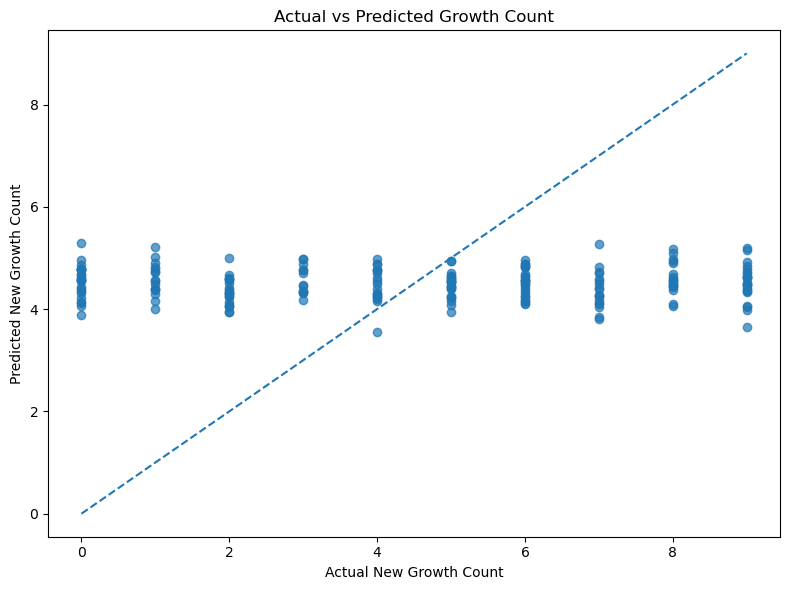

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual New Growth Count")
plt.ylabel("Predicted New Growth Count")
plt.title("Actual vs Predicted Growth Count")
plt.tight_layout()
plt.show()

Target distribution check cheddam

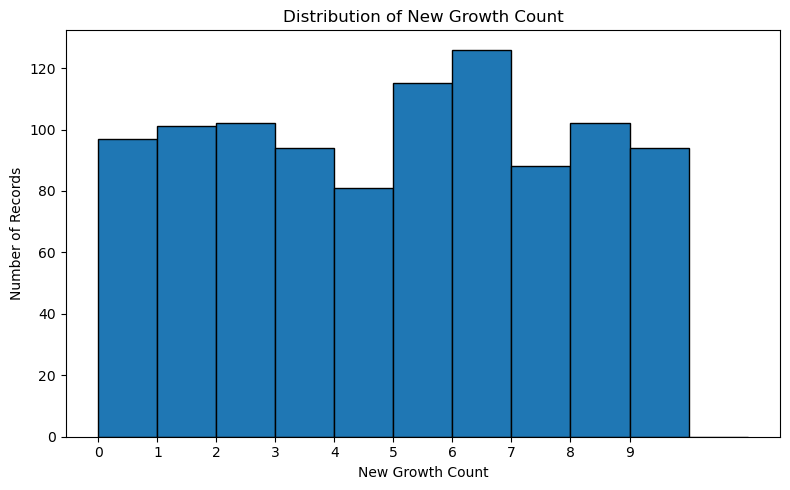

Target mean: 4.52
Target standard deviation: 2.84

Target value counts:
New_Growth_Count
0     97
1    101
2    102
3     94
4     81
5    115
6    126
7     88
8    102
9     94
Name: count, dtype: int64


In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    y,
    bins=range(0, 12),
    edgecolor="black"
)

plt.xlabel("New Growth Count")
plt.ylabel("Number of Records")
plt.title("Distribution of New Growth Count")
plt.xticks(range(0, 10))
plt.tight_layout()
plt.show()

print("Target mean:", round(y.mean(), 2))
print("Target standard deviation:", round(y.std(), 2))
print("\nTarget value counts:")
print(y.value_counts().sort_index())

Actual target values vs predictions check cheddam

In [30]:
# Compare actual and predicted growth counts

comparison = pd.DataFrame({
    "Actual Growth Count": y_test.values,
    "Predicted Growth Count": y_pred
})

comparison["Prediction Error"] = (
    comparison["Actual Growth Count"]
    - comparison["Predicted Growth Count"]
)

print("First 15 Actual vs Predicted values:")
print(comparison.head(15).round(2))

First 15 Actual vs Predicted values:
    Actual Growth Count  Predicted Growth Count  Prediction Error
0                     5                    4.52              0.48
1                     8                    4.97              3.03
2                     4                    4.70             -0.70
3                     5                    4.72              0.28
4                     9                    4.72              4.28
5                     2                    4.59             -2.59
6                     2                    4.34             -2.34
7                     0                    4.32             -4.32
8                     2                    4.58             -2.58
9                     9                    4.79              4.21
10                    1                    4.39             -3.39
11                    4                    4.60             -0.60
12                    7                    4.27              2.73
13                    7                

Random Forest model ni 33 features tho test cheddam

In [31]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=5
)

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

# Calculate metrics
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Model Performance")
print("--------------------------------")
print("MAE:", round(rf_mae, 2))
print("MSE:", round(rf_mse, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 2))

Random Forest Model Performance
--------------------------------
MAE: 2.59
MSE: 8.96
RMSE: 2.99
R2 Score: -0.04


Health_Notes column investigate cheddam

In [32]:
print("Health Notes data type:")
print(analysis_df["Health_Notes"].dtype)

print("\nNumber of unique notes:")
print(analysis_df["Health_Notes"].nunique())

print("\nFirst 15 health notes:")
print(analysis_df["Health_Notes"].head(15))

Health Notes data type:
object

Number of unique notes:
7

First 15 health notes:
0     Yellowing leaves
1                  NaN
2       Brittle leaves
3              New bud
4              Wilting
5                  NaN
6          Strong stem
7          Strong stem
8                  NaN
9                  NaN
10                 NaN
11             Wilting
12    Yellowing leaves
13             Wilting
14    Dark green color
Name: Health_Notes, dtype: object


Health Notes categories check

In [33]:
print("All Health Notes categories with counts:")

print(
    analysis_df["Health_Notes"]
    .value_counts(dropna=False)
)

All Health Notes categories with counts:
Health_Notes
New bud             154
Wilting             129
Yellowing leaves    126
Leaf drop           125
Brittle leaves      121
NaN                 118
Strong stem         117
Dark green color    110
Name: count, dtype: int64


Important observation
- New bud highest frequency: 154.
- Dark green color lowest frequency: 110.
- 118 records lo Health Notes missing unnayi.
- Ee column plant condition gurinchi additional information ivvachu.
Kaani oka doubt undhi: New bud lanti notes New_Growth_Count tho directly related ayi undochu. Kabatti mundhu relationship check cheddam.

Health Notes vs New Growth Count

In [34]:
health_analysis = (
    analysis_df.groupby("Health_Notes", dropna=False)["New_Growth_Count"]
    .agg(["count", "mean", "std"])
    .round(2)
)

print("Health Notes vs New Growth Count:")
print(health_analysis)

Health Notes vs New Growth Count:
                  count  mean   std
Health_Notes                       
Brittle leaves      121  4.42  2.82
Dark green color    110  4.85  2.71
Leaf drop           125  4.52  2.89
New bud             154  4.58  2.81
Strong stem         117  4.41  3.07
Wilting             129  4.49  2.81
Yellowing leaves    126  4.70  2.83
NaN                 118  4.18  2.84


Health_Notes ni input features lo add cheddham

In [37]:
encoded_features = [
    col for col in df.columns
    if col.startswith("Soil_Type_")
    or col.startswith("Fertilizer_Type_")
    or col.startswith("Pest_Severity_")
    or col.startswith("Sunlight_Exposure_")
    or col.startswith("Pest_Presence_")
]

In [38]:
health_encoded = pd.get_dummies(
    analysis_df["Health_Notes"],
    prefix="Health_Notes",
    dtype=int
)

print(health_encoded.head())
print("Shape:", health_encoded.shape)

   Health_Notes_Brittle leaves  Health_Notes_Dark green color  \
0                            0                              0   
1                            0                              0   
2                            1                              0   
3                            0                              0   
4                            0                              0   

   Health_Notes_Leaf drop  Health_Notes_New bud  Health_Notes_Strong stem  \
0                       0                     0                         0   
1                       0                     0                         0   
2                       0                     0                         0   
3                       0                     1                         0   
4                       0                     0                         0   

   Health_Notes_Wilting  Health_Notes_Yellowing leaves  
0                     0                              1  
1                     0         

Health_Notes features ni existing dataset ki add cheddham

In [39]:
df = pd.concat([df, health_encoded], axis=1)

print("Updated Dataset Shape:", df.shape)
print("Health Notes Columns:")

print([
    col for col in df.columns
    if col.startswith("Health_Notes_")
])

Updated Dataset Shape: (1000, 44)
Health Notes Columns:
['Health_Notes_Brittle leaves', 'Health_Notes_Dark green color', 'Health_Notes_Leaf drop', 'Health_Notes_New bud', 'Health_Notes_Strong stem', 'Health_Notes_Wilting', 'Health_Notes_Yellowing leaves']


ML features update cheddham

In [40]:
encoded_features = [
    col for col in df.columns
    if col.startswith("Soil_Type_")
    or col.startswith("Fertilizer_Type_")
    or col.startswith("Pest_Severity_")
    or col.startswith("Sunlight_Exposure_")
    or col.startswith("Pest_Presence_")
    or col.startswith("Health_Notes_")
]

In [41]:
features = [col for col in numeric_features if col in df.columns] + encoded_features
features = list(dict.fromkeys(features))

print("Total Features:", len(features))
print("Features:", features)

Total Features: 40
Features: ['Height_cm', 'Leaf_Count', 'Watering_Amount_ml', 'Watering_Frequency_days', 'Room_Temperature_C', 'Humidity_%', 'Fertilizer_Amount_ml', 'Soil_Moisture_%', 'Soil_Type_Chalky', 'Soil_Type_Clay', 'Soil_Type_Loamy', 'Soil_Type_Peaty', 'Soil_Type_Sandy', 'Soil_Type_Silty', 'Fertilizer_Type_Chemical', 'Fertilizer_Type_Compost', 'Fertilizer_Type_Liquid feed', 'Fertilizer_Type_No fertilizer', 'Fertilizer_Type_Organic', 'Pest_Severity_High', 'Pest_Severity_Low', 'Pest_Severity_Moderate', 'Pest_Severity_None', 'Sunlight_Exposure_3h direct morning sun', 'Sunlight_Exposure_6h full sun', 'Sunlight_Exposure_Filtered sunlight through curtain', 'Sunlight_Exposure_Indirect light all day', 'Sunlight_Exposure_Low light corner', 'Pest_Presence_Aphids', 'Pest_Presence_Fungus gnats', 'Pest_Presence_No pest', 'Pest_Presence_Spider mites', 'Pest_Presence_Whiteflies', 'Health_Notes_Brittle leaves', 'Health_Notes_Dark green color', 'Health_Notes_Leaf drop', 'Health_Notes_New bud', 

Updated training data prepare cheddham

In [42]:
target = "New_Growth_Count"

X = df[features].apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(df[target], errors="coerce")

model_data = pd.concat([X, y.rename(target)], axis=1).dropna()

X = model_data[features]
y = model_data[target]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (1000, 40)
Target Shape: (1000,)


Train-Test Split

In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Input:", X_train.shape)
print("Testing Input:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Input: (800, 40)
Testing Input: (200, 40)
Training Target: (800,)
Testing Target: (200,)


Linear Regression Model Training

In [44]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Training Completed!")

Linear Regression Model Training Completed!


Model Evaluation

In [45]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

MAE: 2.56
MSE: 8.9
RMSE: 2.98
R2 Score: -0.03


Random Forest model test cheddham

In [46]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("MAE:", round(rf_mae, 2))
print("MSE:", round(rf_mse, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 2))

Random Forest Results
MAE: 2.59
MSE: 8.99
RMSE: 3.0
R2 Score: -0.04


In [47]:
features = [
    col for col in features
    if not col.startswith("Health_Notes_")
]

X = df[features]

y = df["New_Growth_Count"]

print("Total Features:", len(features))
print("X Shape:", X.shape)
print("y Shape:", y.shape)

Total Features: 33
X Shape: (1000, 33)
y Shape: (1000,)


In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Input:", X_train.shape)
print("Testing Input:", X_test.shape)

Training Input: (800, 33)
Testing Input: (200, 33)


In [49]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Final Linear Regression Model Trained Successfully!")

Final Linear Regression Model Trained Successfully!


In [50]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Final Linear Regression Results")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

Final Linear Regression Results
MAE: 2.55
MSE: 8.73
RMSE: 2.95
R2 Score: -0.01


In [51]:
correlations = df[features + ["New_Growth_Count"]].corr()

target_corr = correlations["New_Growth_Count"].drop("New_Growth_Count")

print("Feature Correlations with New Growth Count:")
print(target_corr.abs().sort_values(ascending=False).round(3))

Feature Correlations with New Growth Count:
Fertilizer_Type_No fertilizer                          0.045
Pest_Presence_No pest                                  0.045
Fertilizer_Type_Compost                                0.044
Pest_Presence_Fungus gnats                             0.043
Pest_Presence_Spider mites                             0.043
Soil_Moisture_%                                        0.031
Pest_Severity_None                                     0.030
Sunlight_Exposure_Filtered sunlight through curtain    0.029
Height_cm                                              0.029
Soil_Type_Sandy                                        0.027
Pest_Presence_Aphids                                   0.025
Soil_Type_Chalky                                       0.022
Soil_Type_Clay                                         0.021
Pest_Presence_Whiteflies                               0.020
Pest_Severity_Low                                      0.019
Fertilizer_Amount_ml                     

the final steps of plant project

In [54]:
import joblib

joblib.dump(model, "model/plant_growth_model.pkl")
joblib.dump(features, "model/feature_names.pkl")

print("Model and Features Saved Successfully!")

Model and Features Saved Successfully!
